# Set 15: EDA + MLP Regression with Randomized Search

**Q1 → Exp 1A / 1B / 2** · **Q2 → Exp 5** (MLP regression)

Datasets: Q1 `Solar.csv`. Q2 asks for `Solar-regression.csv`, which we don't have, so this uses **`Kasol.csv`**, predicting its continuous `Solar` column (the same stand-in as Set 5).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Solar.csv")
print(df.shape)
df.head()

(228, 7)


,Latitude,Longitude,Altitude,min Temo,Max Temp,Sunshine Hour,Solar Radiation
0,34.08,74.79,1730,-0.9,4.3,0.450000,0
1,34.08,74.79,1730,-0.2,7.6,0.464286,0
2,34.08,74.79,1730,2.6,14.2,0.521429,0
3,34.08,74.79,1730,1.8,8.1,0.542857,0
4,34.08,74.79,1730,7.5,20.4,0.628571,0


### Q1.2 Identify the numerical columns: min, max and mean

In [3]:
num = df.select_dtypes("number")
print("Numerical columns:", list(num.columns))
pd.DataFrame({"min": num.min(), "max": num.max(), "mean": num.mean().round(2)})

Numerical columns: ['Latitude', 'Longitude', 'Altitude', 'min Temo', 'Max Temp', 'Sunshine Hour', 'Solar Radiation']


,min,max,mean
Latitude,8.280000,34.08,20.02
Longitude,72.150000,92.72,78.86
Altitude,2.000000,1730.00,320.00
min Temo,-0.900000,29.70,21.95
Max Temp,4.300000,41.10,29.82
Sunshine Hour,0.428571,11.00,1.73
Solar Radiation,0.000000,1.00,0.50


### Q1.3 Min-max normalisation of a numerical feature, analysed with a scatter plot

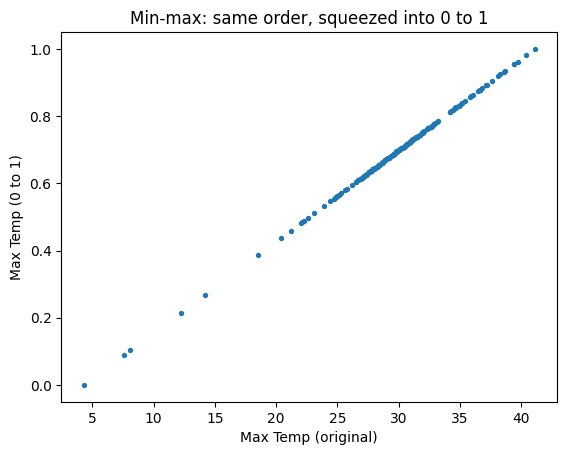

In [4]:
col = "Max Temp"
df[col + "_minmax"] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
plt.scatter(df[col], df[col + "_minmax"], s=8)
plt.xlabel(col + " (original)")
plt.ylabel(col + " (0 to 1)")
plt.title("Min-max: same order, squeezed into 0 to 1")
plt.show()

### Q1.4 Label encoding of a categorical feature
Solar.csv has no text column, so make one (temperature level) and encode it.

In [5]:
df["TempLevel"] = pd.cut(df["Max Temp"], bins=3, labels=["Low", "Medium", "High"])
from sklearn.preprocessing import LabelEncoder

print("Before:", df["TempLevel"].unique()[:6])
df["TempLevel"] = LabelEncoder().fit_transform(df["TempLevel"].astype(str))
print("After :", df["TempLevel"].unique()[:6])

Before: ['Low', 'Medium', 'High']
Categories (3, object): ['Low' < 'Medium' < 'High']
After : [1 2 0]


### Q1.5 Remove features with low variance

In [6]:
from sklearn.feature_selection import VarianceThreshold

num = df.select_dtypes("number").drop(columns=["Max Temp_minmax", "TempLevel"])   # only the original columns
print(num.var().round(3))
vt = VarianceThreshold(threshold=0.3).fit(num)
print("\nKept   :", list(num.columns[vt.get_support()]))
print("Removed:", list(num.columns[~vt.get_support()]))

Latitude               36.801
Longitude              33.851
Altitude           184001.656
min Temo               32.802
Max Temp               23.253
Sunshine Hour           6.958
Solar Radiation         0.251
dtype: float64

Kept   : ['Latitude', 'Longitude', 'Altitude', 'min Temo', 'Max Temp', 'Sunshine Hour']
Removed: ['Solar Radiation']


---
## Question 2

### Q2.1 Read and divide into training (75%) and testing (25%)

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

data = pd.read_csv("data/Kasol.csv").dropna()                 # drop the empty lines (and 14 rows with missing Rainfall)
X = StandardScaler().fit_transform(data.drop(columns=["Unnamed: 0", "Solar"]))   # drop the date and the target
y = data["Solar"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5468, 6)  Test: (1823, 6)


### Q2.2 Build the prediction model
### Q2.3 Evaluate on the test set: MSE and RMSE

*One code cell below answers both parts.*

In [8]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

model = MLPRegressor(hidden_layer_sizes=(32,), max_iter=300, early_stopping=True, random_state=42).fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("MSE :", round(mse, 4))
print("RMSE:", round(np.sqrt(mse), 4))

MSE : 18.9464
RMSE: 4.3527


### Q2.4 Plot the actual and predicted values

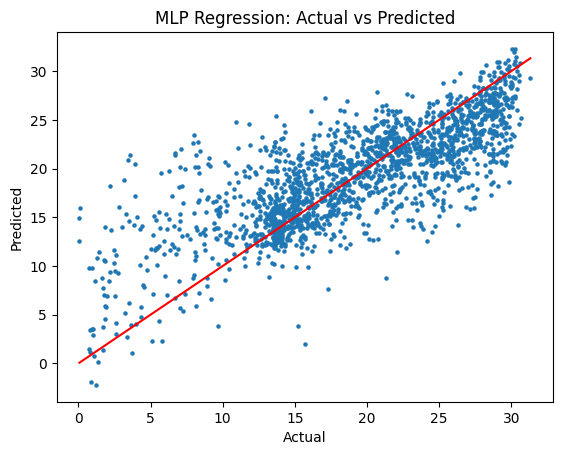

In [9]:
plt.scatter(y_test, y_pred, s=5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("MLP Regression: Actual vs Predicted")
plt.show()

### Q2.5 Improve with Randomized Search CV and display the optimal hyperparameters

In [10]:
from sklearn.model_selection import RandomizedSearchCV

params = {"hidden_layer_sizes": [(32,), (64,), (64, 32)], "alpha": [0.0001, 0.001, 0.01], "learning_rate_init": [0.001, 0.01]}
rand = RandomizedSearchCV(MLPRegressor(max_iter=300, early_stopping=True, random_state=42), params,
                          n_iter=5, cv=3, random_state=42).fit(X_train, y_train)
print("Optimal hyperparameters (Randomized):", rand.best_params_)
rmse_rand = np.sqrt(mean_squared_error(y_test, rand.predict(X_test)))
print("RMSE after Randomized Search:", round(rmse_rand, 4))

Optimal hyperparameters (Randomized): {'learning_rate_init': 0.01, 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
RMSE after Randomized Search: 4.3519


### Q2.6 Compare the results

{'MLP (default)': np.float64(4.352747101352028), 'MLP (Randomized Search)': np.float64(4.351851242445318)}


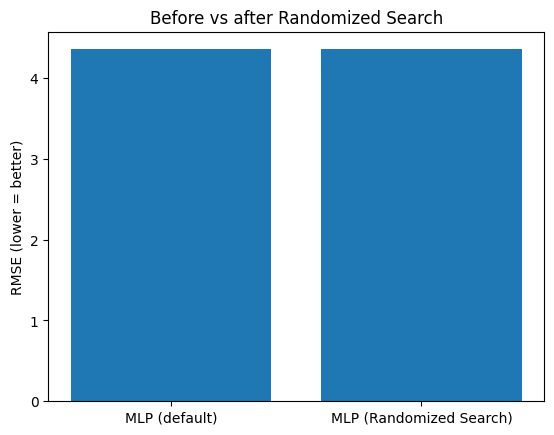

In [11]:
rmse = {"MLP (default)": np.sqrt(mse), "MLP (Randomized Search)": rmse_rand}
print(rmse)
plt.bar(rmse.keys(), rmse.values())
plt.ylabel("RMSE (lower = better)")
plt.title("Before vs after Randomized Search")
plt.show()